# Introduction to Data Science and Systems 2026-2027
## Lab 5 (Week 8): Bayes' Rule 
#### 
---
#### MSc Data Science, University of Glasgow


## What this lab is for

This lab notebook is for you to apply in practice some of the probability concepts seen in class. 

It should take about **30 minutes**. **Lab 5 will count towards your course grade.**

## How the labs work (reminder)

* Questions are labelled **Task N**. Each one has an **answer cell** that starts out containing

      # YOUR CODE HERE
      raise NotImplementedError()

  Replace **both** of those lines with your answer. **Only edit cells that contain
  `# YOUR CODE HERE`** - changing anything else can corrupt the notebook and cost you marks.

* Note: Do not import additional python packages in your answers. The labs will never require it, 
and it will be penalised. 

* After a task there are one or more **test cells** (you cannot edit these). Run them to check your
  answer:
  * a green **&check; [n marks]** box means the test passed;
  * a red **&cross; Test failed** box means it did not.

* Some tests are **hidden**. Running a hidden test cell shows *nothing* now; it is only scored later.
  So "no output" from a test cell is normal and does **not** mean something is wrong.

* Before you finish, always use **Kernel &rarr; Restart Kernel and Run All Cells**, then check the
  marks summary at the bottom.

* When finished, submit your notebook to Moodle for marking. **Make sure to submit your work before the end of the session!**



Now import the packages the autograder needs. **Make sure you run this cell.**

In [1]:
## Standard imports -- run this cell!
from __future__ import print_function, division
import os

# course grading utilities
%pip install -U --force-reinstall --no-cache https://github.com/pugeault/jhwutils/zipball/master
from jhwutils.checkarr import array_hash, check_hash, check_string, check_scalar
from jhwutils.matrices import print_matrix
import jhwutils.tick as tick
import jhwutils.image_audio as ia
from unittest.mock import patch

# numpy
import numpy as np

# plotting 
import matplotlib as mpl
import matplotlib.pyplot as plt

version_id = "v20262027a"

# for printouts
silent = False

# reset the visible marks counter
tick.reset_marks()

print("Everything imported OK")


Defaulting to user installation because normal site-packages is not writeable
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for jhwutils: filename=jhwutils-1.4.0-py3-none-any.whl size=46870 sha256=94a02c9d7d8df4f7a51ef03124179a978b30d0fefa833e2fed205915352450bf
  Stored in directory: C:\Users\3188758P\AppData\Local\Temp\pip-ephem-wheel-cache-kx17jbdf\wheels\4d\0d\ce\7741fa18c491f96ea9c5eccb7b787d7264de88ca395518d1be
Successfully built jhwutils
  Attempting uninstall: jhwutils
    Found existing installation: jhwutils 1.4.0
    Uninstalling jhwutils-1.4.0:
      Successfully uninstalled jhwutils-1.4.0
Note: you may need to restart the kernel to use updated packages.
Everything imported OK


In [2]:
# This cell is used for grading purposes. Do not modify it.


---
## Task 0 &mdash; Tell us who you are

Set the two variables below:

* `student_id` &mdash; your 8-character student ID (for example `"1234567s"`).
* `student_typewritten_signature` &mdash; your full name, for example `"Ada Lovelace"`. Typing your
  name is your declaration that this notebook is your own work.

This is your first answer cell: replace the `# YOUR CODE HERE` / `raise NotImplementedError()` lines
with your answer, then run the test cell that follows.


In [3]:
student_id = "3188758p"                     # your 8-char student id, e.g. "1234567s"
student_typewritten_signature = "Subhranshu Panda"  # your full name, e.g. "Ada Lovelace"



In [4]:

with tick.marks(0):  # no credit for knowing your own id -- this is just a format check
    assert len(student_id) == 8

with tick.marks(0):
    assert len(student_typewritten_signature) > 0



## Hunt the submarine - gridworld version

The USS Scorpion has been lost at sea. Your job is to model where it might be probabilistically. 

<img src="imgs/scorpion.jpg" width="50%">

In this lab, we will assume that our world is divided into a 2D grid of squares, each of which might contain an errant submarine.

<img src="imgs/sea_grid.png" width="50%">

### Part 1 Random variables, outcomes and events

We assume that the submarine's location is given by a random variable $Z$ whose sample space is the space of 2D grid points $\mathbf{z}=[x,y]$ where $x$ and $y$ are integers in the range 0-15 (inclusive). (Be careful: the `x,y` order is the opposite of the `row, column` format used in images).

You are given a probability mass function as a 16x16 matrix `submarine_pmf` giving the probability of each grid square, i.e $f_Z(\mathbf{z}) = P(Z=\mathbf{z})$. 

**Note:** As we have seen in class, this is effectively equivalent to a joint probability $P(X=x, Y=y)$ of two random variables $X$ and $Y$. 


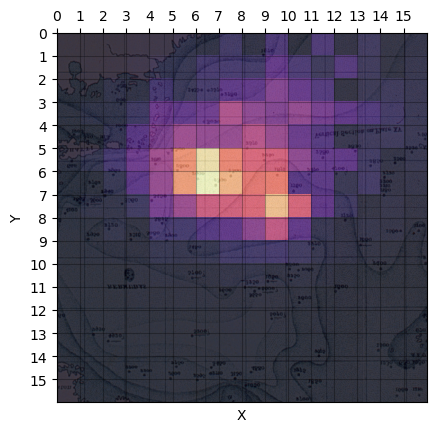

In [5]:
# import submarine data and functions
from submarine import submarine_pmf, show_pmf

show_pmf(submarine_pmf) # show the PMF on top of a map

### Task 1 – Outcomes and events *[8 marks in total]*
Compute the the following values, all of which are scalars. The notation $[x_1, y_1] \rightarrow [x_2, y_2]$ indicates a box that should **include** $x_1,y_1,x_2,y_2$ (be careful!).

* `in_3_4` probability submarine is in square $[3,4]$
* `out_2_4` probability submarine is *not* in square $[2,4]$
* `west_4` submarine is in square $[x \geq 4, y]$
* `below_above` submarine is in square $[x,y<6]$ or $[x,y\geq 10]$
* `box` submarine is in the box $[2, 2] \rightarrow [4, 5]$ (inclusive!)
* `odds_not_box` the *odds* that the submarine is *not* in the box $[2, 4] \rightarrow [6,10]$
* `logit_4_6` the *log-odds (logits)* that the submarine is in square $[4, 6]$
* `dlogit_box` the *change* in log-odds from the hypothesis that the submarine is in the box $[1,1] \rightarrow [5, 5]$ to being in the box $[10,10] \rightarrow [15,15]$

*Reminder:* The odds are given by $\frac{p}{1-p}$ and the log-odds by $\log \frac{p}{1-p} = \log p - \log (1-p)$

In [6]:
in_3_4 = submarine_pmf[3, 4]
out_2_4 = 1 - submarine_pmf[2, 4]
west_4 = np.sum(submarine_pmf[4:, :])
below_above = np.sum(submarine_pmf[:, :6]) + np.sum(submarine_pmf[:, 10:])
box = np.sum(submarine_pmf[2:5, 2:6])

p_box = np.sum(submarine_pmf[2:7, 4:11])
odds_not_box = (1 - p_box) / p_box

p_46 = submarine_pmf[4, 6]
logit_4_6 = np.log(p_46 / (1 - p_46))

p_a = np.sum(submarine_pmf[1:6, 1:6])
p_b = np.sum(submarine_pmf[10:16, 10:16])
dlogit_box = np.log(p_b / (1 - p_b)) - np.log(p_a / (1 - p_a))

In [7]:
with tick.marks(1):
    assert check_scalar(in_3_4, '0xab7461d'), "ERROR: in_3_4 is wrong!"

In [8]:
with tick.marks(1):
    assert check_scalar(out_2_4, '0x15e5225d'), "ERROR: out_2_4 is wrong!"

In [9]:
with tick.marks(1):
    assert check_scalar(west_4, '0x1d40485b'), "ERROR: west_4 is wrong!"

In [10]:
with tick.marks(1):
    assert check_scalar(below_above, '0x15bb18c6'), "ERROR: below_above is wrong!"

In [11]:
with tick.marks(1):
    assert check_scalar(box, '0x52bfb590'), "ERROR: box is wrong!"

In [12]:
with tick.marks(1):
    assert (check_scalar(odds_not_box, '0xccfc0501')), "ERROR: odds_not_box is wrong!"
    

In [13]:
with tick.marks(1):
    assert (check_scalar(logit_4_6, '0x2e63d2e9')), "ERROR: logit_4_6 is wrong!"

In [14]:
# Hidden test checking dlogit_box [1 marks]

### Task 2 – Expected value *[4 marks in total]*
You need to plan for the search operation. There is a fixed search station at square $x=2, y=5$. Assume the Euclidean ($L_2$) norm in measuring distances. The time $t$ in hours to search a grid square from the station is given by $t = d^2 + 3d + 2$. Compute:

* `expected_location` Expected value of the submarine location.
* `expected_distance` expected value of the distance of the submarine to this fixed station 
* `total_search_time` the **total** search time required to search the every square on the entire grid. Assume each search of a grid square has to restart from the station.
* `expected_search_time` expected search time of a random search starting at the station.

*Reminder:* The expectation of a function is given by: 

$$ E[f(X)] = \sum_x f(x) \cdot p(X=x) $$

**REMEMBER**, in general $$E[f(X)] \neq f(E[X]).$$

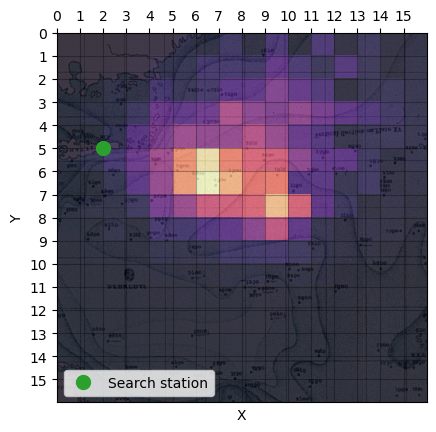

In [15]:
show_pmf(submarine_pmf)
plt.plot(2,5, 'C2o', label='Search station', markersize=10)
plt.legend(loc='lower left');
plt.show()

In [16]:
# This function defines the time for searching a grid square at a distance d from 
# the base station. 

def search_time_for_distance(d): 
    return d**2 + 3*d + 2

# we define the base station position at x=2 and y=5
base = np.array((2,5))

In [17]:
pmf = submarine_pmf
expected_distance = 0
total_search_time = 0
expected_search_time = 0
expected_location = np.zeros(2,)

for i in range(16):
    for j in range(16):
        d = np.linalg.norm(np.array([i, j]) - base)
        p = pmf[i, j]
        expected_location += p * np.array([i, j])
        expected_distance += p * d
        t = search_time_for_distance(d)
        total_search_time += t
        expected_search_time += p * t

In [18]:
print(f'''
- Expected Location: E[x] = {expected_location[0]}, E[y] = {expected_location[1]}
- Expected Distance: E[d] = {expected_distance}
- Expected Search Time: E[t] = {expected_search_time}
- Total Search Time: T = {total_search_time}
''')


- Expected Location: E[x] = 7.577816231120855, E[y] = 5.753628250188578
- Expected Distance: E[d] = 6.6236411084897595
- Expected Search Time: E[t] = 75.6723908507334
- Total Search Time: T = 26926.962779618698



In [19]:
with tick.marks(1):
    assert check_scalar(expected_location[0], '0x4f9f5e7c') , "ERROR: expected_location x is wrong!"
    assert check_scalar(expected_location[1], '0x8805a495') , "ERROR: expected_location y is wrong!"

In [20]:
with tick.marks(1):
    assert check_scalar(expected_distance, '0xbe7903de'), "ERROR: expected distance is wrong!"

In [21]:
with tick.marks(1):
    assert check_scalar(total_search_time, '0xcc0cd6c2'), "ERROR: total_search_time is wrong!"

In [22]:
# Hidden test checking expected_search_time [1 mark]

### Task 3 – Conditional probability *[3 marks in total]*
The search strategy could be improved if one of the $x$ or $y$ coordinates were known for sure (e.g. from another source, like satellite imaging). To identify how *much* this would help, we can use conditional probability distributions. Compute the following:


* `p_x_y` the *conditional* PMF of an finding the submarine on an x coordinate given a y coordinate $P(X=x|Y=y)$ as 16x16 matrix
* `p_y_x` the *conditional* PMF of finding the submarine on a y coordinate given an x coordinate $P(Y=y|X=x)$ as 16x16 matrix
* `p_y_4` the conditional PMF of the submarine being in squares with y=4, as a single 16 element vector.

In [23]:
p_x_y = submarine_pmf / np.sum(submarine_pmf, axis=0, keepdims=True)
p_y_x = submarine_pmf / np.sum(submarine_pmf, axis=1, keepdims=True)
p_y_4 = submarine_pmf[:, 4] / np.sum(submarine_pmf[:, 4])

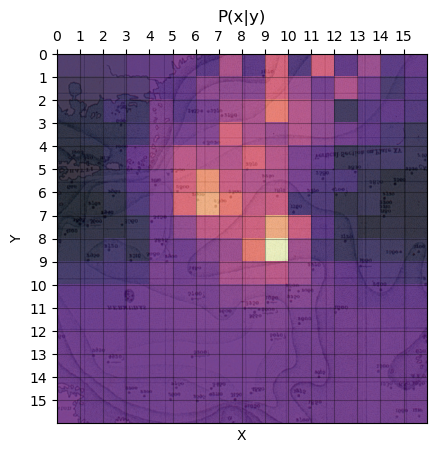

In [24]:
with tick.marks(1):    
    show_pmf(p_x_y, "P(x|y)")
    assert check_hash(p_x_y, ((16, 16), 2103.534977619737)) , "ERROR: p_x_y is wrong!"

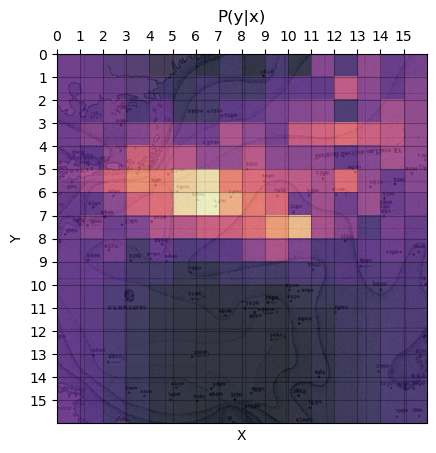

In [25]:
with tick.marks(1):
    show_pmf(p_y_x, "P(y|x)")
    assert check_hash(p_y_x, ((16, 16), 2031.7414411989753)), "ERROR: p_y_x is wrong!"    

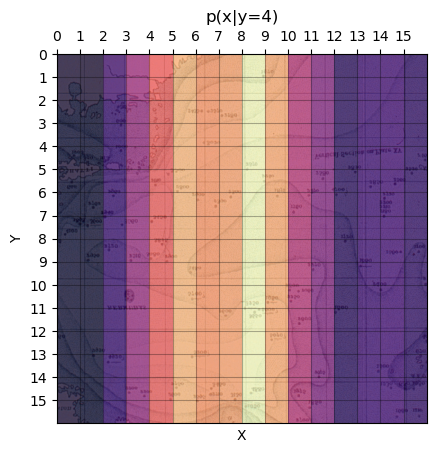

In [26]:
with tick.marks(1):
    show_pmf(p_y_4[:,None], 'p(x|y=4)')
    assert check_hash(p_y_4, ((16,), 8.640152386889147 ))   , "ERROR: p_y_4 is wrong!" 

### Task 4 – Entropy [2 marks]
The search could be guided more intelligently if we could work out how informative getting one of the coordinates could be. For example, knowing which `x` coordinate would give you *most* information about the `y` coordinate?  
In pratice, the `x` coordinate that give you the most information is the one that has the smallest entropy.

For this task, you are asked to: 

1. Compute the entropy of each conditional distribution $H(Y|X=x)$ for each $x$ and store it in `entropy_y`.

2. Store the most useful `x` coordinate to know in `most_informative_x`.

*Reminder:* The entropy is calculated by: 

$$
H(X) = - \sum_x p(X=x) \log_2 p(X=x)
$$

*Note:* the binary logarithm can be calculated using the Numpy function `np.log2`

In [27]:
entropy_y = -np.sum(p_y_x * np.log2(p_y_x), axis=1)
most_informative_x = np.argmin(entropy_y)

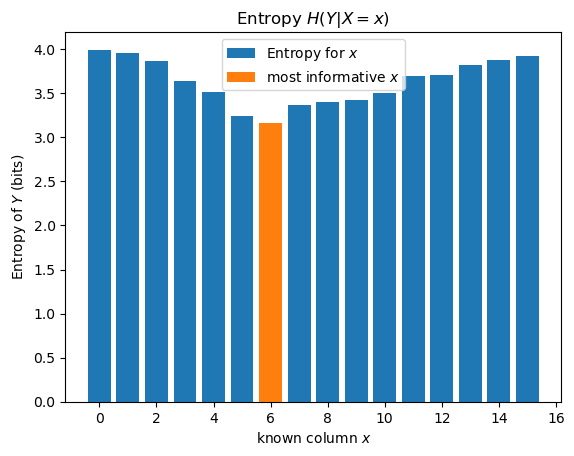

In [28]:
plt.bar(range(len(entropy_y)), entropy_y, color='C0', label='Entropy for $x$')
plt.bar(most_informative_x, entropy_y[most_informative_x], color='C1', label='most informative $x$')
plt.xlabel('known column $x$')
plt.ylabel('Entropy of $Y$ (bits)')
plt.title(r'Entropy $H(Y|X=x)$')
plt.legend()
plt.show()

In [29]:
with tick.marks(1):
    assert check_hash(entropy_y, ((16,), 509.16360658756037)), "ERROR: The entropy_y is wrong!"

In [30]:
#Sanity check; just to check size
with tick.marks(0):
    assert check_hash(0.0*most_informative_x, ((), 0.0 )), "ERROR: 'most_informative_x' has the wrong shape, should be a scalar!"

In [31]:
# Hidden test checking most_informative_x 

## Part 2 – Bayes' rule

In this part we will be using Bayes' rule to update our belief in where the submarine is when a new observation is made. Remember that Bayes' rule is defined as: 

$$
P(H|D) = \frac{P(D|H)P(H)}{P(D)}
$$
Where: 

- $P(H|D)$ is called the *posterior*: the belief that the hypothesis $H$ is true if the data $D$ is observed.
- $P(H)$ is called the *prior*: our confidence that the hypothesis is correct before observing the data.
- $P(D|H)$ is called the *likelihood*: how likely it is to observe this data if the hypothesis were true.
- $P(D)$ is called the *evidence*: how likely it is to observe the data irrespective of the hypothesis.

The evidence $P(D)$ is often calculated by integrating over the evidence: 

$$P(D) = \sum_h P(D|H=h)P(H=h)$$

In the case of our submarine, you are provided with the function `search_submarine(x,y)`, which returns the **likelihood** for the submarine's location, given an `x` and `y` coordinate to search at, based on sonar returns from a search ship. It returns this as a 16x16 matrix. 

### Task 5 – Calculating the posterior [1 mark]

Using `submarine_pmf` as a prior, compute the posterior PMF using the result of `search_submarine(10, 7)` as likelihood. Store the result in `submarine_posterior`.

In [32]:
from submarine import search_submarine

likelihood = search_submarine(10, 7)
evidence = np.sum(likelihood * submarine_pmf)
submarine_posterior = likelihood * submarine_pmf / evidence

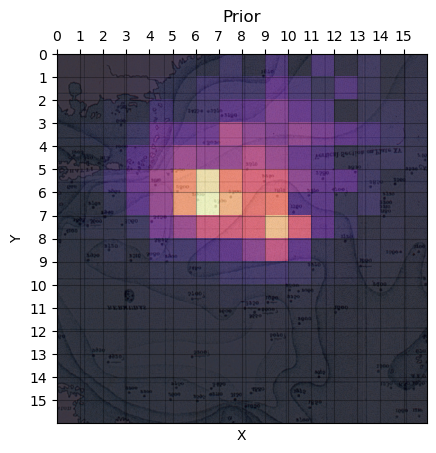

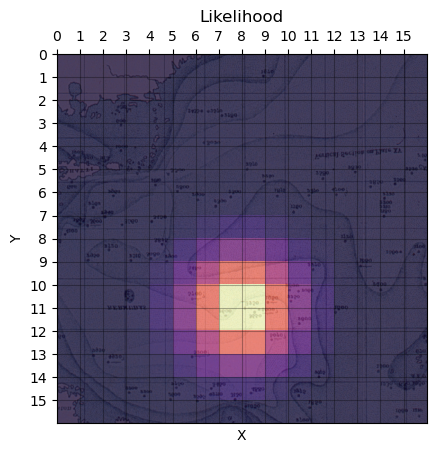

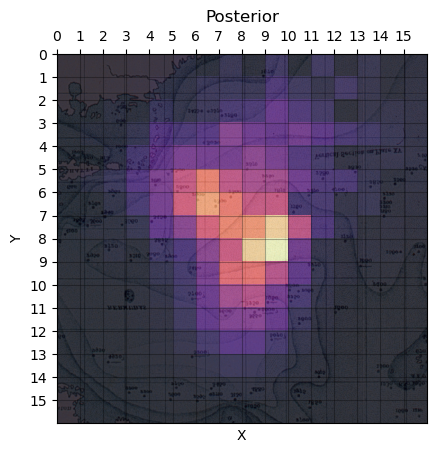

In [33]:
show_pmf(submarine_pmf, 'Prior')
show_pmf(search_submarine(10,7), 'Likelihood' )
show_pmf(submarine_posterior, 'Posterior')

In [34]:
with tick.marks(1):
    assert check_hash(submarine_posterior, ((16, 16), 129.2249265521699))

### Task 6 – Sequential searching [2 marks]

Compute the posterior distribution after searching the each of squares y=5, x=0..15 (i.e. testing *each* of these 16 squares in turn, and combining *all* of the evidence into a posterior), storing the posteriors as a list, *starting with the prior* and ending with the posterior after observing y=5, x=15. You should have a 17 elements list of 16x16 matrices. Store this as `search_strip_posterior`

In [35]:

# we initialise our posterior as the prior (the same PMF we used before)
posterior = submarine_pmf

# we will append the posteriors after each update to this list
search_strip_posterior = [posterior]

for x in range(16):
    likelihood = search_submarine(x, 5)
    posterior = likelihood * posterior
    posterior = posterior / np.sum(posterior)
    search_strip_posterior.append(posterior)


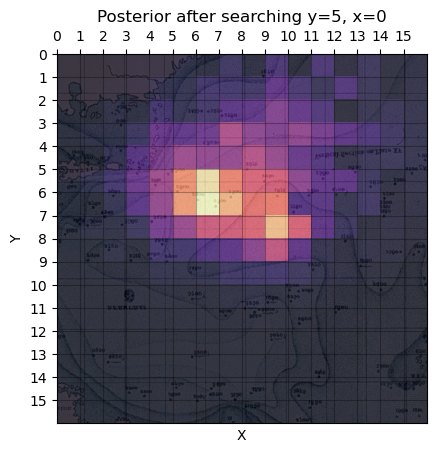

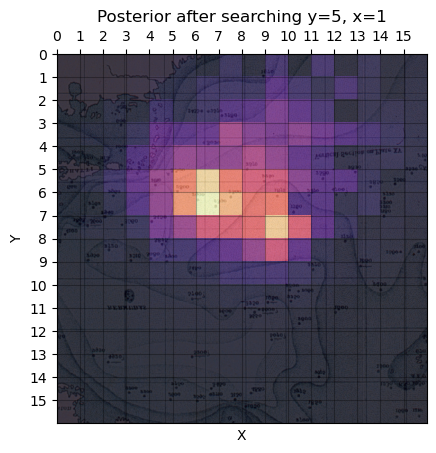

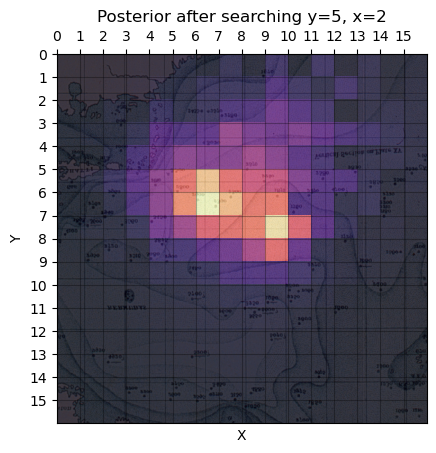

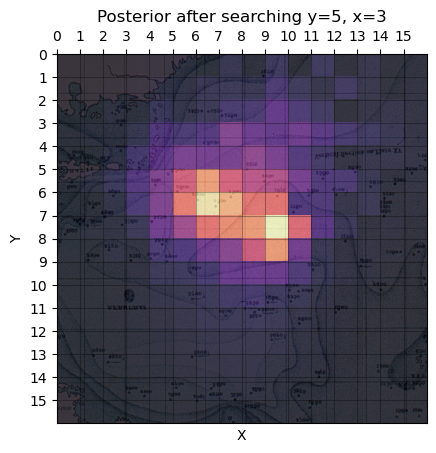

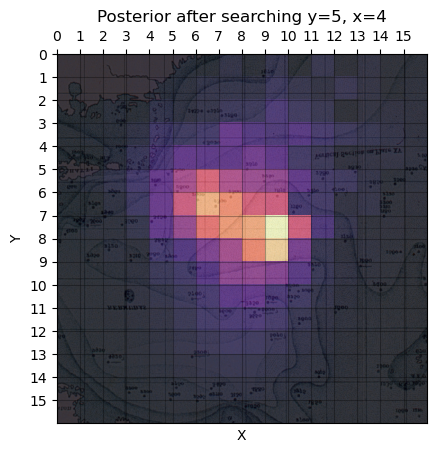

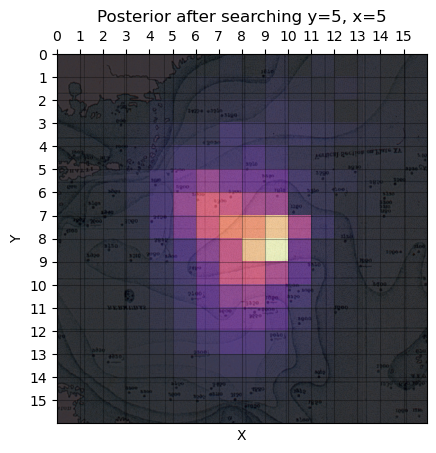

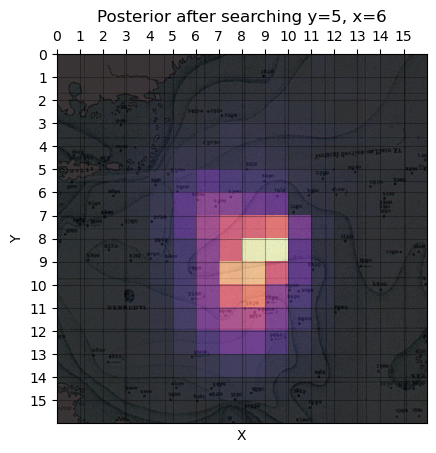

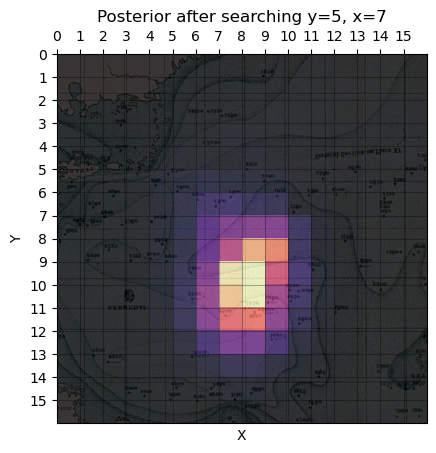

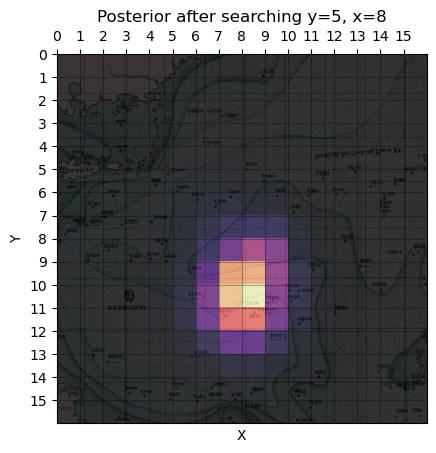

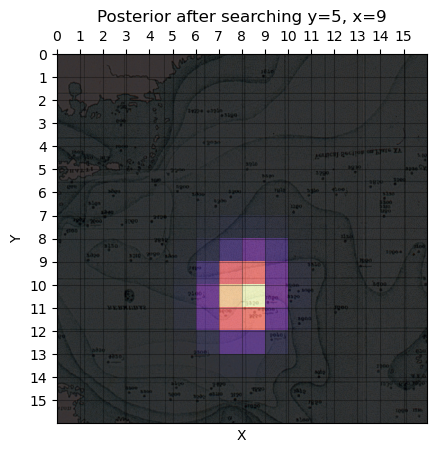

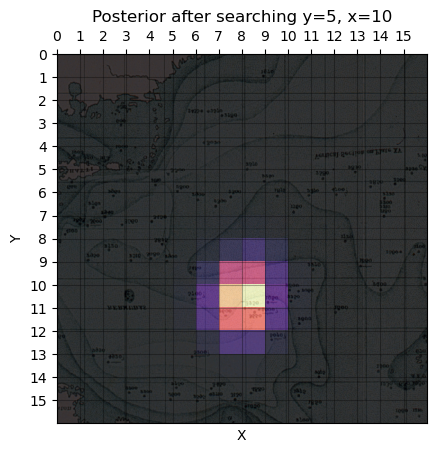

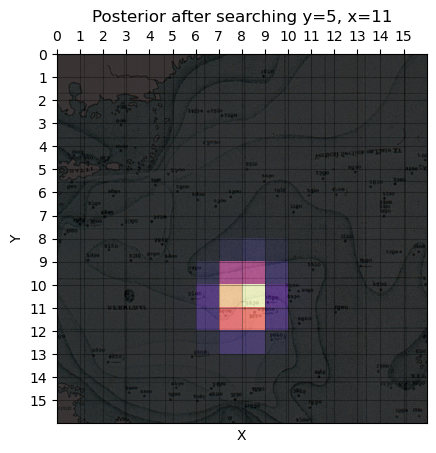

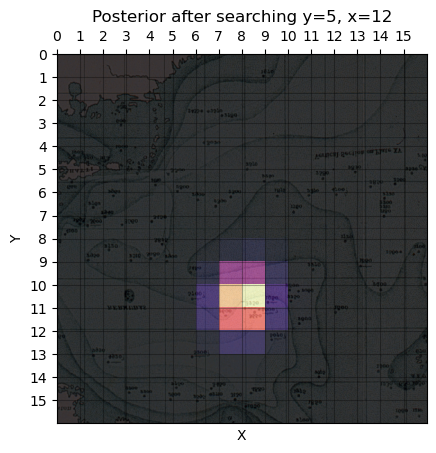

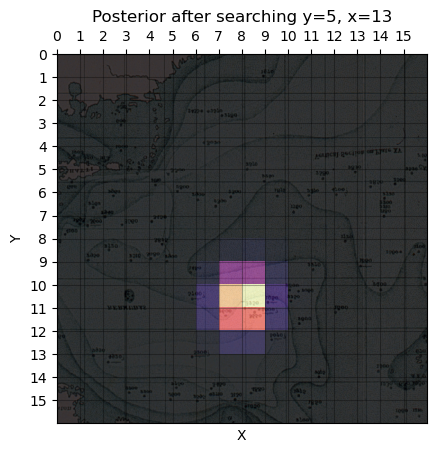

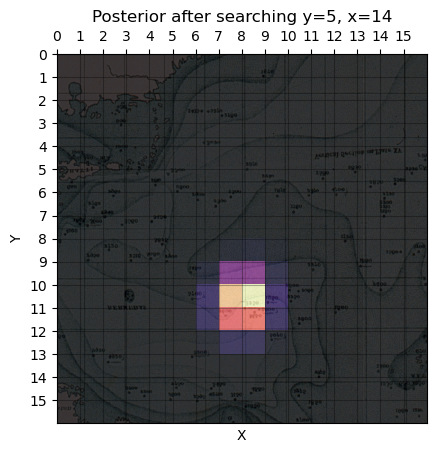

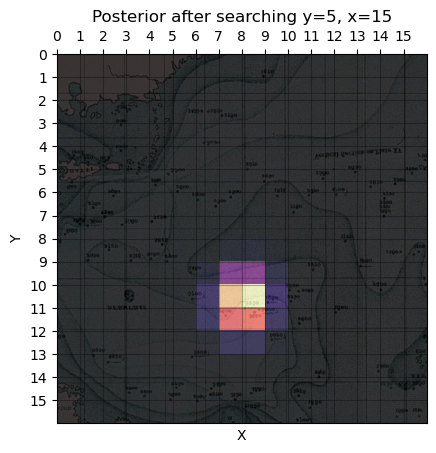

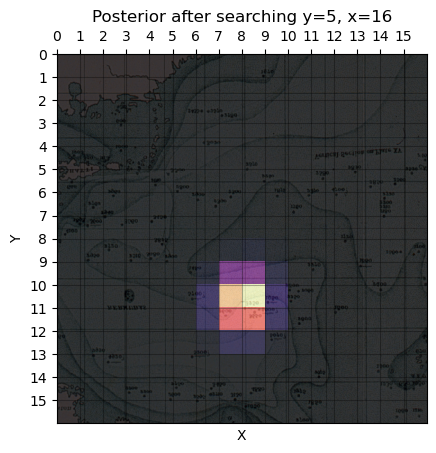

In [36]:
# Sanity check that the size is ok [0 marks]
with tick.marks(0):
    assert(len(search_strip_posterior)==17)
    assert(search_strip_posterior[0].shape==(16, 16)) # only check one of the 17 matricies

    
# Show the 17 individual posteriors
for i, p in enumerate(search_strip_posterior):
    show_pmf(p, f'Posterior after searching y=5, x={i}')

In [37]:
# Hidden test checking search_strip_posterior [2 marks]

---
## Before you finish

1. **Kernel &rarr; Restart Kernel and Run All Cells.** The notebook must run top to bottom with no errors (no red boxes, no tracebacks).
2. Check the **marks summary** below.
3. Upload the completed `.ipynb` to Moodle. 



# Appendix: Marks summary

Run **Kernel &rarr; Restart Kernel and Run All Cells** before reading this, or it will be out of date.


In [38]:
print("Marks available: 20  (visible with feedback: 15,  hidden: 5)")

# tick.summarise_marks() only reads the id-based tick.Marks() records, which this
# lab does not use; summarise from the counters tick.marks() maintains instead.
import IPython.display
if tick.available_marks > 0:
    IPython.display.display(IPython.display.HTML(
        """<!--{id:"TOTALMARK",marks:"%d", available:"%d"}  -->
        <div class="alert alert-box alert-success">
        <h1> Marks in this run: %d/%d (%.1f%%) </h1> </div>"""
        % (tick.total_marks, tick.available_marks,
           tick.total_marks, tick.available_marks,
           tick.total_marks / tick.available_marks * 100)))
else:
    print("No marks recorded -- use Kernel -> Restart Kernel and Run All Cells.")


Marks available: 20  (visible with feedback: 15,  hidden: 5)
